<a href="https://colab.research.google.com/github/mhoyor/ckd-risk-app/blob/main/notebooks/02_diagnostic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 Diagnostic analysis: factors that distinguish CKD (PB3)
Group 5 PROHI: Risk Factor Prediction of Chronic Kidney Disease

User: Attending Nephrologist.

Questions
1. which factors distinguish patients with CKD from patients without?

2. Is there a statistical association between diabetes, hypertension and CKD? How do markers such as blood glucose, blood urea and serum creatinine differ between the groups?

This is cross-sectional data (one visit per patient), so it shows **associations**, not causes. Some factors (for example anaemia) can be a consequence of CKD rather than a cause.

In [ ]:
GITHUB_USER = "mhoyor"

%cd /content
!rm -rf ckd-risk-app
!git clone https://github.com/{GITHUB_USER}/ckd-risk-app.git
%cd /content/ckd-risk-app

/content
Cloning into 'ckd-risk-app'...
remote: Enumerating objects: 38, done.
remote: Counting objects: 100% (38/38), done.
remote: Compressing objects: 100% (37/37), done.
remote: Total 38 (delta 14), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (38/38), 28.90 KiB | 5.78 MiB/s, done.
Resolving deltas: 100% (14/14), done.
/content/ckd-risk-app


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import fisher_exact, chi2_contingency, mannwhitneyu
from sklearn.tree import DecisionTreeClassifier
from data_prep import load_data, FEATURES
from viz import apply_style, COLORS, MUTED, plot_readable_tree

apply_style()
os.makedirs("figures", exist_ok=True)

d = load_data()
df = d["all"]
ckd = df[df["class"] == 1]
non = df[df["class"] == 0]

NAMES = {
    "htn": "Hypertension", "dm": "Diabetes", "cad": "Coronary artery disease",
    "ane": "Anaemia", "pe": "Pedal oedema", "appet": "Poor appetite",
    "rbc": "Abnormal red cells (urine)", "pc": "Abnormal pus cells (urine)",
    "pcc": "Pus cell clumps (urine)", "ba": "Bacteria (urine)", "bp": "Diastolic BP flag",
    "age": "Age", "bp limit": "BP category", "bgr": "Random blood glucose",
    "bu": "Blood urea", "sc": "Serum creatinine", "sod": "Sodium", "pot": "Potassium",
    "hemo": "Haemoglobin", "pcv": "Packed cell volume", "rbcc": "Red blood cell count",
    "wbcc": "White blood cell count", "sg": "Urine specific gravity",
    "al": "Urine albumin", "su": "Urine sugar",
}
BINARY = ["htn", "dm", "cad", "ane", "pe", "appet", "rbc", "pc", "pcc", "ba", "bp"]
ORDERED = ["age", "bp limit", "bgr", "bu", "sc", "sod", "pot", "hemo", "pcv",
           "rbcc", "wbcc", "sg", "al", "su"]
N_TESTS = len(BINARY) + len(ORDERED)
ALPHA = 0.05 / N_TESTS   # Bonferroni correction
print(f"{N_TESTS} tests, Bonferroni-corrected significance level = {ALPHA:.4f}")

25 tests, Bonferroni-corrected significance level = 0.0020


## Step 1: Yes/no factors (comorbidities and urine findings)
For each factor: % of patients with it in each group, Fisher's exact test (exact, so it works even with small counts), and **Cramér's V** as the effect size (0 = no association, 1 = perfect association).

The usual odds ratio cannot be calculated when a group has zero cases (no non-CKD patient has hypertension, for example), so we report a **corrected odds ratio** (0.5 added to every cell, the Haldane–Anscombe correction) with a 95% confidence interval.

In [ ]:
def binary_test(col):
    a = int(ckd[col].sum()); b = len(ckd) - a          # CKD: with / without
    c = int(non[col].sum()); dd = len(non) - c         # non-CKD: with / without
    table = np.array([[a, b], [c, dd]])
    _, p = fisher_exact(table)
    chi2 = chi2_contingency(table, correction=False)[0]
    v = np.sqrt(chi2 / table.sum())
    a2, b2, c2, d2 = a + 0.5, b + 0.5, c + 0.5, dd + 0.5
    odds = (a2 * d2) / (b2 * c2)
    se = np.sqrt(1 / a2 + 1 / b2 + 1 / c2 + 1 / d2)
    return {
        "Factor": NAMES[col],
        "Non-CKD %": round(100 * c / len(non), 1),
        "CKD %": round(100 * a / len(ckd), 1),
        "Corrected OR": round(odds, 1),
        "OR 95% CI": f"{np.exp(np.log(odds) - 1.96 * se):.1f} to {np.exp(np.log(odds) + 1.96 * se):.1f}",
        "p-value": p,
        "Cramér's V": round(v, 2),
        "Significant": "Yes" if p < ALPHA else "No",
    }

binary_results = pd.DataFrame([binary_test(c) for c in BINARY]).sort_values("Cramér's V", ascending=False)
binary_results.style.format({"p-value": "{:.1e}"}).hide(axis="index")

Factor,Non-CKD %,CKD %,Corrected OR,OR 95% CI,p-value,Cramér's V,Significant
Hypertension,0.000000,60.900000,225.400000,13.7 to 3720.6,1.7e-21,0.600000,Yes
Diabetes,0.000000,54.700000,174.700000,10.6 to 2882.0,1.7e-18,0.550000,Yes
Abnormal pus cells (urine),0.000000,35.200000,79.000000,4.8 to 1305.5,6.6e-11,0.400000,Yes
Poor appetite,0.000000,31.200000,66.400000,4.0 to 1097.9,1.5e-09,0.370000,Yes
Pedal oedema,0.000000,27.300000,55.100000,3.3 to 912.7,2.8e-08,0.350000,Yes
Anaemia,0.000000,25.000000,48.800000,2.9 to 810.9,2.6e-07,0.330000,Yes
Pus cell clumps (urine),0.000000,21.100000,39.300000,2.4 to 654.6,2.2e-06,0.300000,Yes
Abnormal red cells (urine),0.000000,19.500000,35.700000,2.1 to 596.3,7.6e-06,0.280000,Yes
Coronary artery disease,0.000000,17.200000,30.600000,1.8 to 513.1,3.1e-05,0.260000,Yes
Bacteria (urine),0.000000,8.600000,14.200000,0.8 to 244.5,8.2e-03,0.180000,No


## Step 2: Lab markers (ordered ranges)
The lab values are ranges, converted to ordered codes, so we use the **Mann–Whitney U test** (it compares the order of values, not averages). Effect size: **rank-biserial correlation r**, from −1 to +1. Positive = higher in CKD, negative = lower in CKD.

In [ ]:
def ordered_test(col):
    x, y = ckd[col], non[col]
    u, p = mannwhitneyu(x, y, alternative="two-sided")
    r = 2 * u / (len(x) * len(y)) - 1
    return {
        "Marker": NAMES[col],
        "Rank-biserial r": round(r, 2),
        "Direction in CKD": "higher" if r > 0 else "lower",
        "p-value": p,
        "Significant": "Yes" if p < ALPHA else "No",
    }

ordered_results = pd.DataFrame([ordered_test(c) for c in ORDERED])
ordered_results = ordered_results.reindex(ordered_results["Rank-biserial r"].abs().sort_values(ascending=False).index)
ordered_results.style.format({"p-value": "{:.1e}"}).hide(axis="index")

Marker,Rank-biserial r,Direction in CKD,p-value,Significant
Haemoglobin,-0.940000,lower,1.1e-28,Yes
Packed cell volume,-0.900000,lower,1.2e-26,Yes
Urine specific gravity,-0.780000,lower,2.4e-21,Yes
Red blood cell count,-0.750000,lower,7.0e-21,Yes
Urine albumin,0.660000,higher,7.5e-18,Yes
Sodium,-0.600000,lower,1.1e-13,Yes
Blood urea,0.560000,higher,4.0e-13,Yes
Random blood glucose,0.430000,higher,7.7e-08,Yes
Age,0.320000,higher,1.3e-04,Yes
Serum creatinine,0.320000,higher,9.7e-08,Yes


## Step 3: Effect-size chart (the main figure for this use case)
With this dataset almost every test is significant, so p-values alone say little. This chart ranks every factor by **how strongly** it differs between the groups.
- Left: yes/no factors (Cramér's V, all more common in CKD).
- Right: lab markers. Orange bars to the right = higher in CKD; blue bars to the left = lower in CKD (higher in non-CKD).
- Hollow bars are not significant after Bonferroni correction.

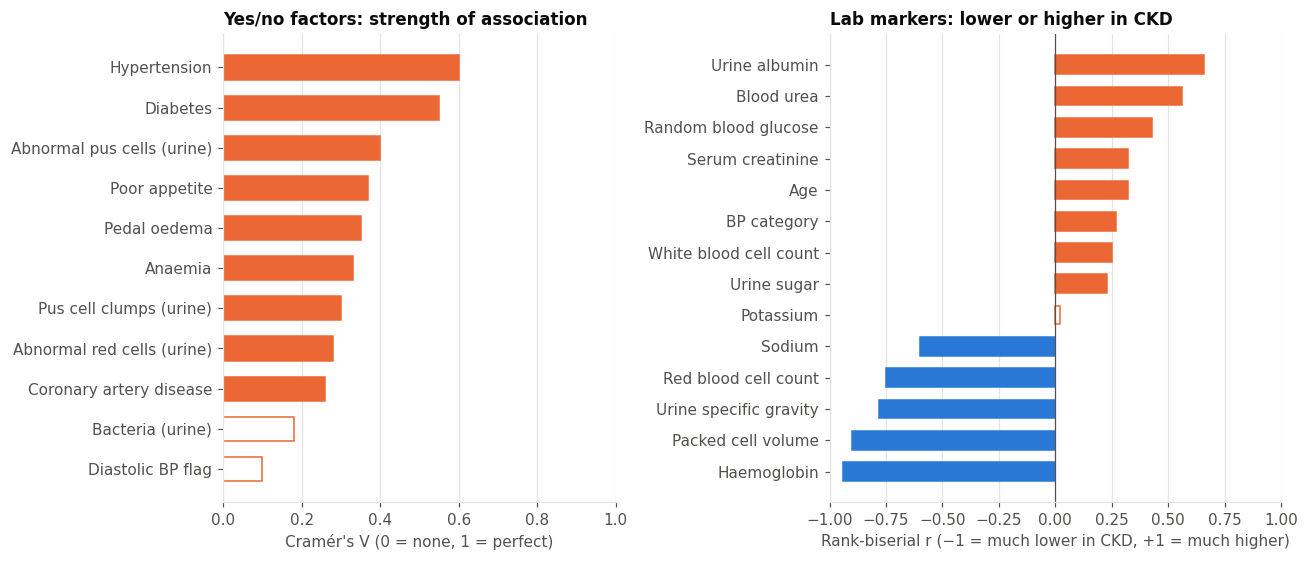

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.2), gridspec_kw={"width_ratios": [1, 1.15]})

b = binary_results.sort_values("Cramér's V")
fill = [COLORS["CKD"] if s == "Yes" else "white" for s in b["Significant"]]
ax1.barh(b["Factor"], b["Cramér's V"], color=fill, edgecolor=COLORS["CKD"], height=0.6)
ax1.set_xlim(0, 1)
ax1.set_title("Yes/no factors: strength of association")
ax1.set_xlabel("Cramér's V (0 = none, 1 = perfect)")
ax1.grid(axis="x"); ax1.grid(axis="y", visible=False)

o = ordered_results.sort_values("Rank-biserial r")
colors = [COLORS["CKD"] if r > 0 else COLORS["Non-CKD"] for r in o["Rank-biserial r"]]
fill = [c if s == "Yes" else "white" for c, s in zip(colors, o["Significant"])]
ax2.barh(o["Marker"], o["Rank-biserial r"], color=fill, edgecolor=colors, height=0.6)
ax2.axvline(0, color=MUTED, linewidth=0.8)
ax2.set_xlim(-1, 1)
ax2.set_title("Lab markers: lower or higher in CKD")
ax2.set_xlabel("Rank-biserial r (−1 = much lower in CKD, +1 = much higher)")
ax2.grid(axis="x"); ax2.grid(axis="y", visible=False)

fig.tight_layout()
fig.savefig("figures/diag_effect_sizes.png")
plt.show()

## Step 4: Which combinations of risk factors are most common in CKD patients?
This answers the second part of the diagnostic question directly: among the 128 CKD patients, how often do hypertension, diabetes, coronary artery disease and anaemia occur together?

In [ ]:
COMBO = {"htn": "Hypertension", "dm": "Diabetes", "cad": "CAD", "ane": "Anaemia"}

def combo_label(row):
    present = [name for col, name in COMBO.items() if row[col] == 1]
    return " + ".join(present) if present else "None of these"

combos = ckd.apply(combo_label, axis=1).value_counts()
combos_table = pd.DataFrame({"CKD patients": combos, "%": (100 * combos / len(ckd)).round(1)})
combos_table

,CKD patients,%
None of these,28,21.9
Hypertension + Diabetes,28,21.9
Hypertension + Diabetes + Anaemia,14,10.9
Hypertension,13,10.2
Diabetes,11,8.6
Hypertension + Diabetes + CAD,10,7.8
Anaemia,7,5.5
Hypertension + Anaemia,4,3.1
Hypertension + Diabetes + CAD + Anaemia,4,3.1
Hypertension + CAD,4,3.1


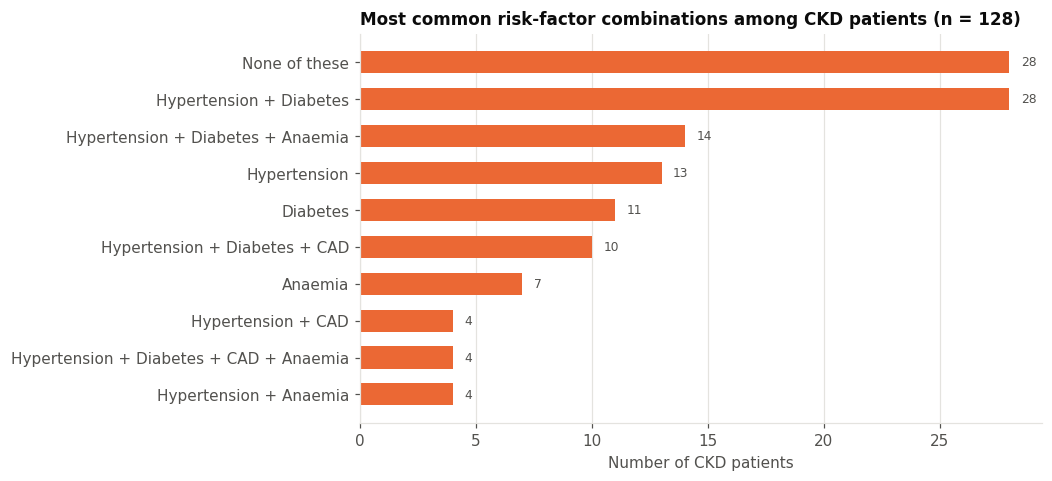

In [ ]:
top = combos.head(10).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.6))
bars = ax.barh(top.index, top.values, color=COLORS["CKD"], height=0.6)
for bar, v in zip(bars, top.values):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2, str(v),
            va="center", fontsize=8, color=MUTED)
ax.set_title("Most common risk-factor combinations among CKD patients (n = 128)")
ax.set_xlabel("Number of CKD patients")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
fig.savefig("figures/diag_combinations.png")
plt.show()

## Step 5: Correlation heatmap
Spearman correlation (suitable for ordered codes) between key markers and CKD (the `class` row). Orange = move together, blue = move in opposite directions.

What to look for: haemoglobin, packed cell volume and red cell count are strongly correlated with each other (they measure similar things), which matters for the predictive models.

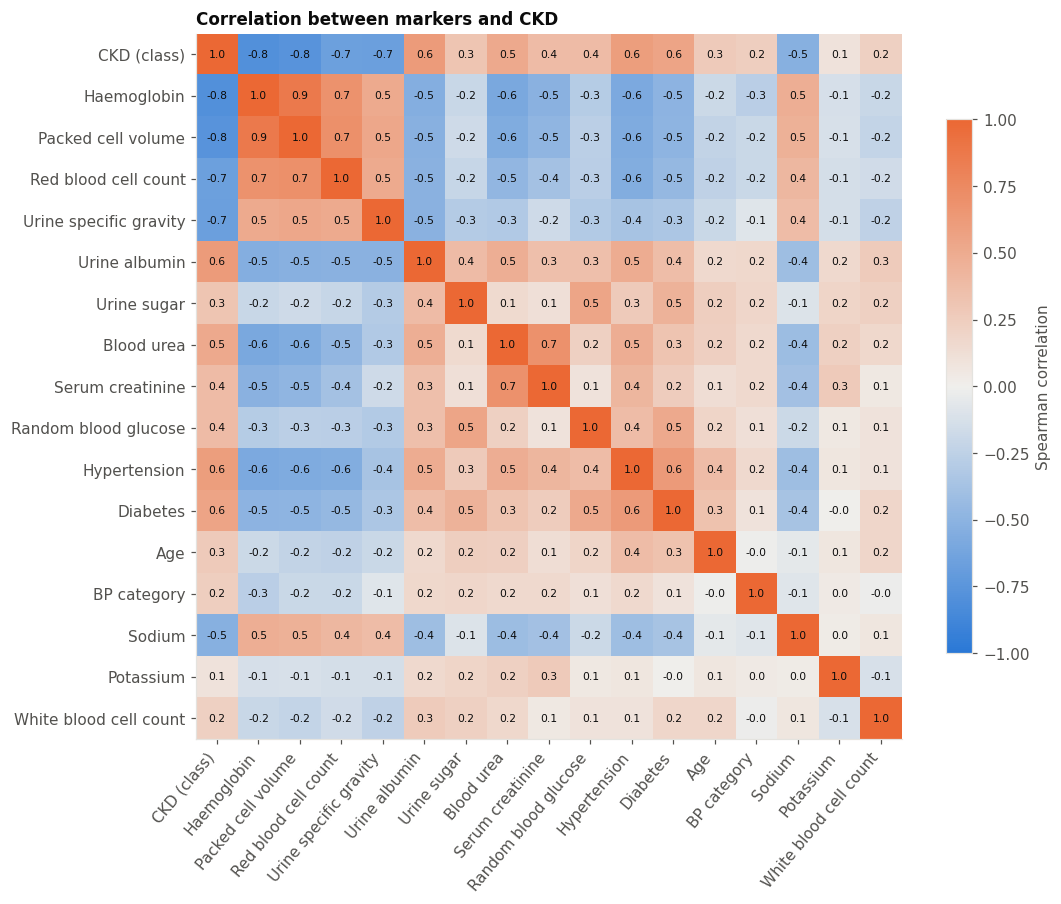

In [ ]:
HEAT = ["class", "hemo", "pcv", "rbcc", "sg", "al", "su", "bu", "sc", "bgr",
        "htn", "dm", "age", "bp limit", "sod", "pot", "wbcc"]
corr = df[HEAT].corr(method="spearman").round(2)
labels = ["CKD (class)"] + [NAMES[c] for c in HEAT[1:]]

cmap = LinearSegmentedColormap.from_list("div", [COLORS["Non-CKD"], "#f0efec", COLORS["CKD"]])
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr.values, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(HEAT))); ax.set_xticklabels(labels, rotation=50, ha="right")
ax.set_yticks(range(len(HEAT))); ax.set_yticklabels(labels)
ax.grid(False)
for i in range(len(HEAT)):
    for j in range(len(HEAT)):
        ax.text(j, i, f"{corr.values[i, j]:.1f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.7, label="Spearman correlation")
ax.set_title("Correlation between markers and CKD")
fig.tight_layout()
fig.savefig("figures/diag_heatmap.png")
plt.show()

## Step 6: Which factors does a simple model rely on?
A decision tree of depth 3, trained on the training set only, shows which questions best separate CKD from non-CKD (the same method as the course Streamlit lab). Each box is one question with the number of patients of each group that reach it; orange boxes are mostly CKD, blue boxes mostly non-CKD (darker = purer).

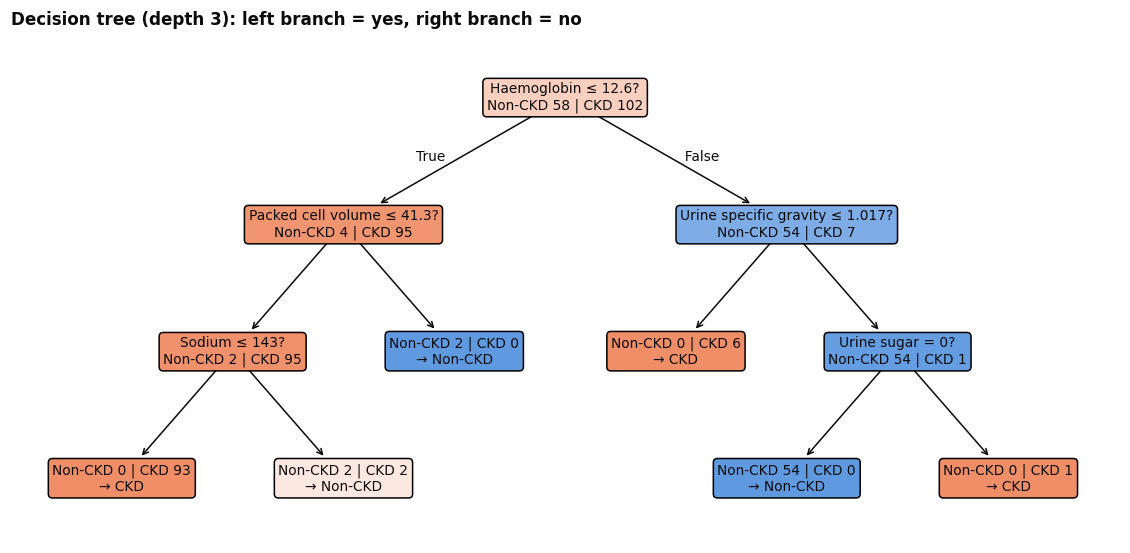

,0
Haemoglobin,0.749
Urine specific gravity,0.145
Packed cell volume,0.052
Urine sugar,0.027
Sodium,0.027


In [ ]:
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(d["train"][FEATURES], d["train"]["class"])

fig, ax = plt.subplots(figsize=(13, 6))
plot_readable_tree(ax, tree, FEATURES, raw=d["raw"], names=NAMES)
ax.set_title("Decision tree (depth 3): left branch = yes, right branch = no")
fig.savefig("figures/diag_tree.png")
plt.show()

importance = pd.Series(tree.feature_importances_, index=[NAMES[f] for f in FEATURES])
importance[importance > 0].sort_values(ascending=False).round(3)

## Step 7: Answers to the nephrologist's questions (copy into the PB3 Trello card and the report)
1. **Diabetes and hypertension are strongly associated with CKD.** Hypertension: 60.9% of CKD patients vs 0% of non-CKD (Fisher p < 0.001, Cramér's V = 0.60). Diabetes: 54.7% vs 0% (V = 0.55). The standard odds ratio is undefined because no non-CKD patient has either condition; the corrected odds ratios are very large (about 225 for hypertension and 175 for diabetes) with very wide confidence intervals, so the exact size of the association is uncertain.
2. **The strongest lab differences are haemoglobin (much lower in CKD, r = −0.94), packed cell volume (−0.90), urine specific gravity (−0.78), red cell count (−0.75) and urine albumin (higher in CKD, +0.66).** Sodium is lower (−0.60) and blood urea higher (+0.56) in CKD. Blood glucose (+0.43) and serum creatinine (+0.32) are also higher in CKD, but less strongly than expected, partly because their ranges are wide. Potassium does not differ.
3. **Common combinations:** hypertension + diabetes is the most common pattern (28 of 128 CKD patients), but another 28 (22%) have none of hypertension, diabetes, CAD or anaemia, so screening on comorbidities alone would miss about one in five CKD patients.
4. **Overlapping markers:** haemoglobin, packed cell volume and red cell count are highly correlated, so they carry largely the same information (anaemia). A simple tree relies mostly on haemoglobin and specific gravity.
5. **Caution:** these are associations in a single-hospital, cross-sectional sample whose non-CKD group has no comorbidities at all; they do not prove causes (anaemia, for example, is a known consequence of CKD), and the effect sizes are probably larger than they would be in a typical clinic population.

## Step 8: Download all figures

In [ ]:
import shutil
from google.colab import files

binary_results.to_csv("figures/diag_binary_tests.csv", index=False)
ordered_results.to_csv("figures/diag_marker_tests.csv", index=False)
combos_table.to_csv("figures/diag_combinations.csv")
shutil.make_archive("diagnostic_figures", "zip", "figures")
files.download("diagnostic_figures.zip")